# Introduction to Machine Learning – Lab 3
## k-Means Clustering with Z-Score Scaling

### Objective
This notebook repeats the clustering of notebook 08 with z-score scaling in place of min-max scaling. Everything before the scaling stays the same, so a difference in the results comes from the scaling alone.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import numpy as np
import pandas as pd
from clustering import (
    N_INIT,
    SEED,
    agreement_table,
    fit_models,
    inertia_table,
    plot_clusters,
    plot_elbow,
    plot_silhouettes,
    plot_variance_shares,
    reduce_to_thresholds,
    silhouette_table,
    variance_by_type,
)
from preprocessing import (
    ORDINAL,
    drop_incomplete,
    fill_missing,
    make_preprocessor,
    make_zscore_scaler,
    prepare_data,
)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

### Data preparation
The houses are loaded, the two houses with whole blocks of empty cells are dropped, the remaining gaps are filled and the categorical features are encoded. Notebook 08 explains these choices.

In [2]:
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

onehot = [col for col in encoded_complete.columns if col not in X_complete.columns]
ordinal = [col for col in encoded_complete.columns if col in ORDINAL]
numeric = [col for col in encoded_complete.columns if col not in onehot + ordinal]
column_types = {"One-hot": onehot, "Ordinal": ordinal, "Numeric": numeric}

assert encoded_complete.isna().sum().sum() == 0
assert len(onehot) + len(ordinal) + len(numeric) == encoded_complete.shape[1]

print(f"{len(encoded_complete):,} houses, {encoded_complete.shape[1]} columns")
print(f"One-hot: {len(onehot)}, ordinal: {len(ordinal)}, numeric: {len(numeric)}")

2,923 houses, 205 columns
One-hot: 151, ordinal: 21, numeric: 33


### Z-score scaling
Z-score scaling replaces every value of a column with `(x - mean) / standard deviation`, using the mean and the standard deviation of that column. A value of +2 then means "two standard deviations above the average house". Every scaled column ends up with mean 0 and standard deviation 1, and unlike min-max scaling there is no fixed lower or upper limit.

The formula raises a question that min-max scaling did not: should the one-hot columns be scaled too? Min-max scaling leaves them at 0/1 by itself, z-score scaling would change them. Both versions are compared here: z-score on all 205 columns, and z-score on the 54 ordinal and numeric columns with the one-hot columns left at 0/1.

,One-hot,Ordinal,Numeric
Z-score on all columns,0.737,0.102,0.161
One-hot left at 0/1,0.134,0.337,0.529


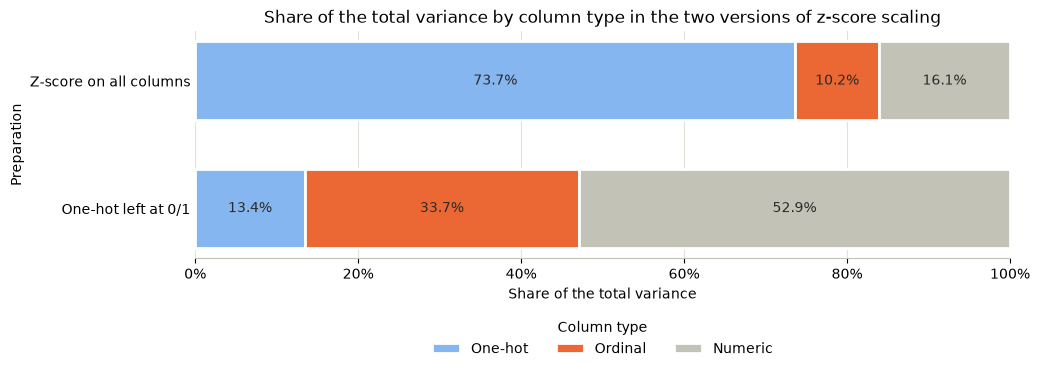

In [3]:
columns = encoded_complete.columns
scaled_columns = ordinal + numeric

# Fitted on all houses: k-means has no train/test split.
# The transformer moves the scaled columns to the front, so the original order is restored
candidates = {
    "Z-score on all columns": make_zscore_scaler(columns).fit_transform(encoded_complete)[columns],
    "One-hot left at 0/1": make_zscore_scaler(scaled_columns).fit_transform(encoded_complete)[columns],
}

variance_shares = pd.DataFrame({name: variance_by_type(data, column_types) for name, data in candidates.items()}).T
display(variance_shares.round(3))
plot_variance_shares(variance_shares, "Share of the total variance by column type in the two versions of z-score scaling")

In [4]:
category_share = encoded_complete[onehot].mean()
rare = category_share[category_share < 0.01]
rarest = category_share.idxmin()

print(f"One-hot columns covering under 1% of the houses: {len(rare)} of {len(onehot)}")
print(f"Rarest one-hot column: {rarest}, {encoded_complete[rarest].sum():.0f} of {len(encoded_complete):,} houses")
print(f"Value of a house with that category after z-score: {candidates['Z-score on all columns'][rarest].max():.1f}")
print("Largest absolute value in each version:")
for name, data in candidates.items():
    largest = data.abs().max()
    print(f"  {name}: {largest.max():.1f} in {largest.idxmax()}")

One-hot columns covering under 1% of the houses: 47 of 151
Rarest one-hot column: MS SubClass_infrequent_sklearn, 1 of 2,923 houses
Value of a house with that category after z-score: 54.1
Largest absolute value in each version:
  Z-score on all columns: 54.1 in Mas Vnr Type_infrequent_sklearn
  One-hot left at 0/1: 32.7 in Misc Val


In [5]:
rows = []
for name, data in candidates.items():
    candidate_pca, candidate_reduced, counts = reduce_to_thresholds(data)
    top_pc1 = pd.Series(np.abs(candidate_pca.components_[0]), index=data.columns).nlargest(5)
    data_at_90 = candidate_reduced[:, : counts[0.90]]
    labels = KMeans(n_clusters=5, n_init=N_INIT, random_state=SEED).fit_predict(data_at_90)
    rows.append(
        {
            "Version": name,
            "Largest absolute value": round(data.abs().max().max(), 1),
            **{f"Components at {t:.0%}": count for t, count in counts.items()},
            "PC1 share": f"{candidate_pca.explained_variance_ratio_[0]:.2%}",
            "Top PC1 columns": ", ".join(top_pc1.index),
            "Cluster sizes (5 clusters, 90%)": sorted(np.bincount(labels).tolist()),
            "Silhouette (5 clusters, 90%)": round(silhouette_score(data_at_90, labels), 3),
        }
    )

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Version").T)

Version,Z-score on all columns,One-hot left at 0/1
Largest absolute value,54.1,32.7
Components at 98%,149,84
Components at 95%,131,61
Components at 90%,112,45
Components at 80%,85,30
PC1 share,8.10%,18.33%
Top PC1 columns,"Year Built, Garage Yr Blt, Overall Qual, Exter Qual, Garage Cars","Overall Qual, Garage Cars, Year Built, Garage Yr Blt, Exter Qual"
"Cluster sizes (5 clusters, 90%)","[151, 523, 578, 649, 1022]","[166, 588, 652, 657, 860]"
"Silhouette (5 clusters, 90%)",0.041,0.097


#### Interpretation of z-score scaling and the one-hot columns
- **What was tried:** z-score scaling on all 205 columns against z-score scaling on the 54 ordinal and numeric columns only. The 5 clusters at 90% in the last table are the number chosen further below. Here it only has to be the same for both versions.
- **What z-score does to a one-hot column:** a category held by a share `p` of the houses turns its 1 into `(1 - p) / sqrt(p * (1 - p))`, so the rarer the category, the larger the value. 47 of the 151 one-hot columns cover under 1% of the houses. The rarest ones belong to a single house of 2,923 and reach 54.1, the largest value in the data, although they only say "this house has an unusual category".
- **What this does to the variance:** every scaled column gets variance 1, so a category of one house counts as much as `Overall Qual`. With 151 of the 205 columns, the one-hot columns then hold 73.7% of the variance.
- **What this does to the results:** the variance spreads over many unrelated columns, so PCA needs 112 components for 90% instead of 45, and PC1 explains 8.10% instead of 18.33%. The silhouette of the 5 clusters drops to 0.041 against 0.097.
- **Choice:** the one-hot columns stay at 0/1. They are already on a range from 0 to 1, comparable to values of a few standard deviations, and a rare category stays a 1. The largest value falls from 54.1 to 32.7, and it now comes from `Misc Val`, a real measurement of an unusual house.
- **Cost of the choice:** the one-hot columns now hold only 13.4% of the variance, against 33.7% for the ordinal and 52.9% for the numeric columns. The 151 columns of neighborhoods, building types and materials therefore influence distances much less than the 54 others. The one-hot columns also keep a mean above 0, so the data is not fully standardized.
- **Rejected:** z-score on all columns. Its top PC1 columns look much the same, but it gives rare categories the largest values in the data, needs far more components and clusters less well.

In [6]:
scaled = candidates["One-hot left at 0/1"]

assert scaled.columns.equals(encoded_complete.columns)
assert scaled[onehot].equals(encoded_complete[onehot])
assert np.allclose(scaled[scaled_columns].mean(), 0) and np.allclose(scaled[scaled_columns].std(ddof=0), 1)

print(f"Columns with mean 0 and standard deviation 1: {len(scaled_columns)}")
print(f"Columns left at 0/1: {len(onehot)}")
print(f"Range of all values: {scaled.min().min():.1f} to {scaled.max().max():.1f}")

Columns with mean 0 and standard deviation 1: 54
Columns left at 0/1: 151
Range of all values: -10.3 to 32.7


### Principal component analysis

In [7]:
pca, reduced, component_counts = reduce_to_thresholds(scaled)
shares = pca.explained_variance_ratio_
cumulative = shares.cumsum()

variance_table = pd.DataFrame(
    {
        "Variance kept": [f"{t:.0%}" for t in component_counts],
        "Components": list(component_counts.values()),
        "Share of the columns": [f"{count / scaled.shape[1]:.1%}" for count in component_counts.values()],
    }
)
top_columns = pd.Series(np.abs(pca.components_[0]), index=scaled.columns).nlargest(6).round(3)

display(variance_table)
print(f"PC1: {shares[0]:.2%}, PC2: {shares[1]:.2%}, PC3: {shares[2]:.2%}")
print("Columns with the largest absolute weight in PC1:")
print(top_columns.to_string())

,Variance kept,Components,Share of the columns
0,98%,84,41.0%
1,95%,61,29.8%
2,90%,45,22.0%
3,80%,30,14.6%


PC1: 18.33%, PC2: 6.91%, PC3: 5.23%
Columns with the largest absolute weight in PC1:
Overall Qual     0.246
Garage Cars      0.229
Year Built       0.228
Garage Yr Blt    0.225
Exter Qual       0.223
Garage Area      0.219


#### Interpretation of the principal components
- **Reduction:** 98% of the variance takes 84 of the 205 columns (41.0%), 95% takes 61, 90% takes 45 and 80% takes 30.
- **First components:** PC1 explains 18.33% of the variance, PC2 6.91% and PC3 5.23%, so PC1 stands out clearly from the rest.
- **What leads PC1:** the largest weights belong to `Overall Qual`, `Garage Cars`, `Year Built`, `Garage Yr Blt`, `Exter Qual` and `Garage Area`, so quality, garage size and age. Their weights are close together, from 0.219 to 0.246, so PC1 is a mix of many related columns and no single column drives it. These are ordinal and numeric columns, which fits their large share of the variance.

### Elbow method

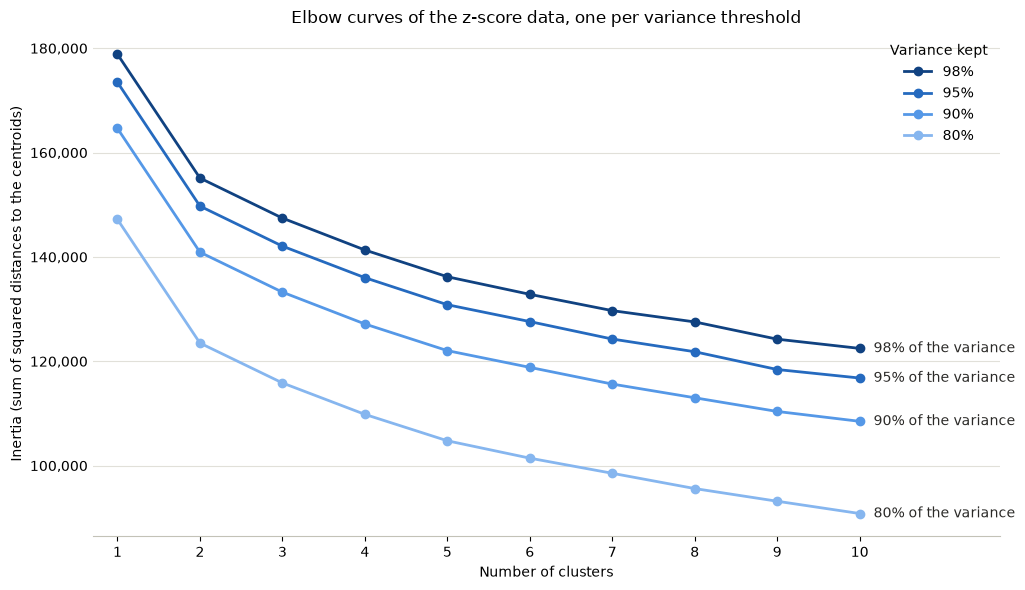

In [8]:
cluster_range = range(1, 11)
inertia = inertia_table(reduced, component_counts, cluster_range)

plot_elbow(inertia, "Elbow curves of the z-score data, one per variance threshold")

In [9]:
drop_per_cluster = inertia.pct_change().dropna().mul(-100).round(1)
drop_per_cluster.index.name = "Cluster added"

kept = pd.Series({f"{t:.0%}": cumulative[count - 1] for t, count in component_counts.items()})
height = pd.DataFrame(
    {
        "Inertia with 1 cluster": inertia.loc[1],
        "Compared with 98%": inertia.loc[1] / inertia.loc[1, "98%"],
        "Variance kept compared with 98%": kept / kept["98%"],
    }
)

print("Inertia:")
display(inertia.round(0).astype(int))
print("Percentage drop in inertia when one more cluster is added:")
display(drop_per_cluster)
print("Height of the curves:")
display(height.round(3))

Inertia:


,98%,95%,90%,80%
Clusters,,,,
1,178845,173465,164629,147187
2,155121,149744,140910,123493
3,147445,142072,133253,115851
4,141332,136026,127153,109827
5,136204,130843,122044,104764
6,132836,127613,118836,101433
7,129710,124264,115634,98534
8,127546,121829,113008,95605
9,124239,118424,110385,93175


Percentage drop in inertia when one more cluster is added:


,98%,95%,90%,80%
Cluster added,,,,
2,13.3,13.7,14.4,16.1
3,4.9,5.1,5.4,6.2
4,4.1,4.3,4.6,5.2
5,3.6,3.8,4.0,4.6
6,2.5,2.5,2.6,3.2
7,2.4,2.6,2.7,2.9
8,1.7,2.0,2.3,3.0
9,2.6,2.8,2.3,2.5
10,1.4,1.4,1.7,2.5


Height of the curves:


,Inertia with 1 cluster,Compared with 98%,Variance kept compared with 98%
98%,178844.791,1.000,1.000
95%,173465.456,0.970,0.970
90%,164628.644,0.921,0.921
80%,147187.221,0.823,0.823


#### Interpretation of the elbow curves
- **Inertia** measures how far the houses lie from the centers of their clusters. Each cluster has a centroid, its mean point, and inertia sums the squared distance of every house to the centroid of its cluster.
- **Why more clusters always lower it:** a house can only get closer to a center when another center is added, so at 90% inertia goes down from 164,629 at one cluster to 108,494 at ten. A falling curve is no proof of real groups. What counts is where the fall weakens.
- **Where the curve bends:** the second cluster takes off 14.4% at 90%, far more than any other. After it the drops are small and even: 5.4%, 4.6% and 4.0% for the third to the fifth cluster. The sixth then takes off 2.6% and the later ones between 1.7% and 2.7%. So the strongest bend is at 2 clusters and a second, much weaker one after 5 clusters.
- **Why the 80% curve is the lowest:** a single cluster has an inertia equal to the variance of the kept components times the number of houses. At 80% that is 147,187, or 0.823 of the 98% value, and the variance kept relative to 98% is also 0.823. Fewer components leave less distance to measure, and the clusters themselves are no tighter.
- **Shape instead of level:** the percentage table is therefore the fair comparison. It shows the same pattern at each threshold, with the sharp first drop between 13.3% and 16.1% and the fifth cluster between 3.6% and 4.6%.

### Silhouette analysis

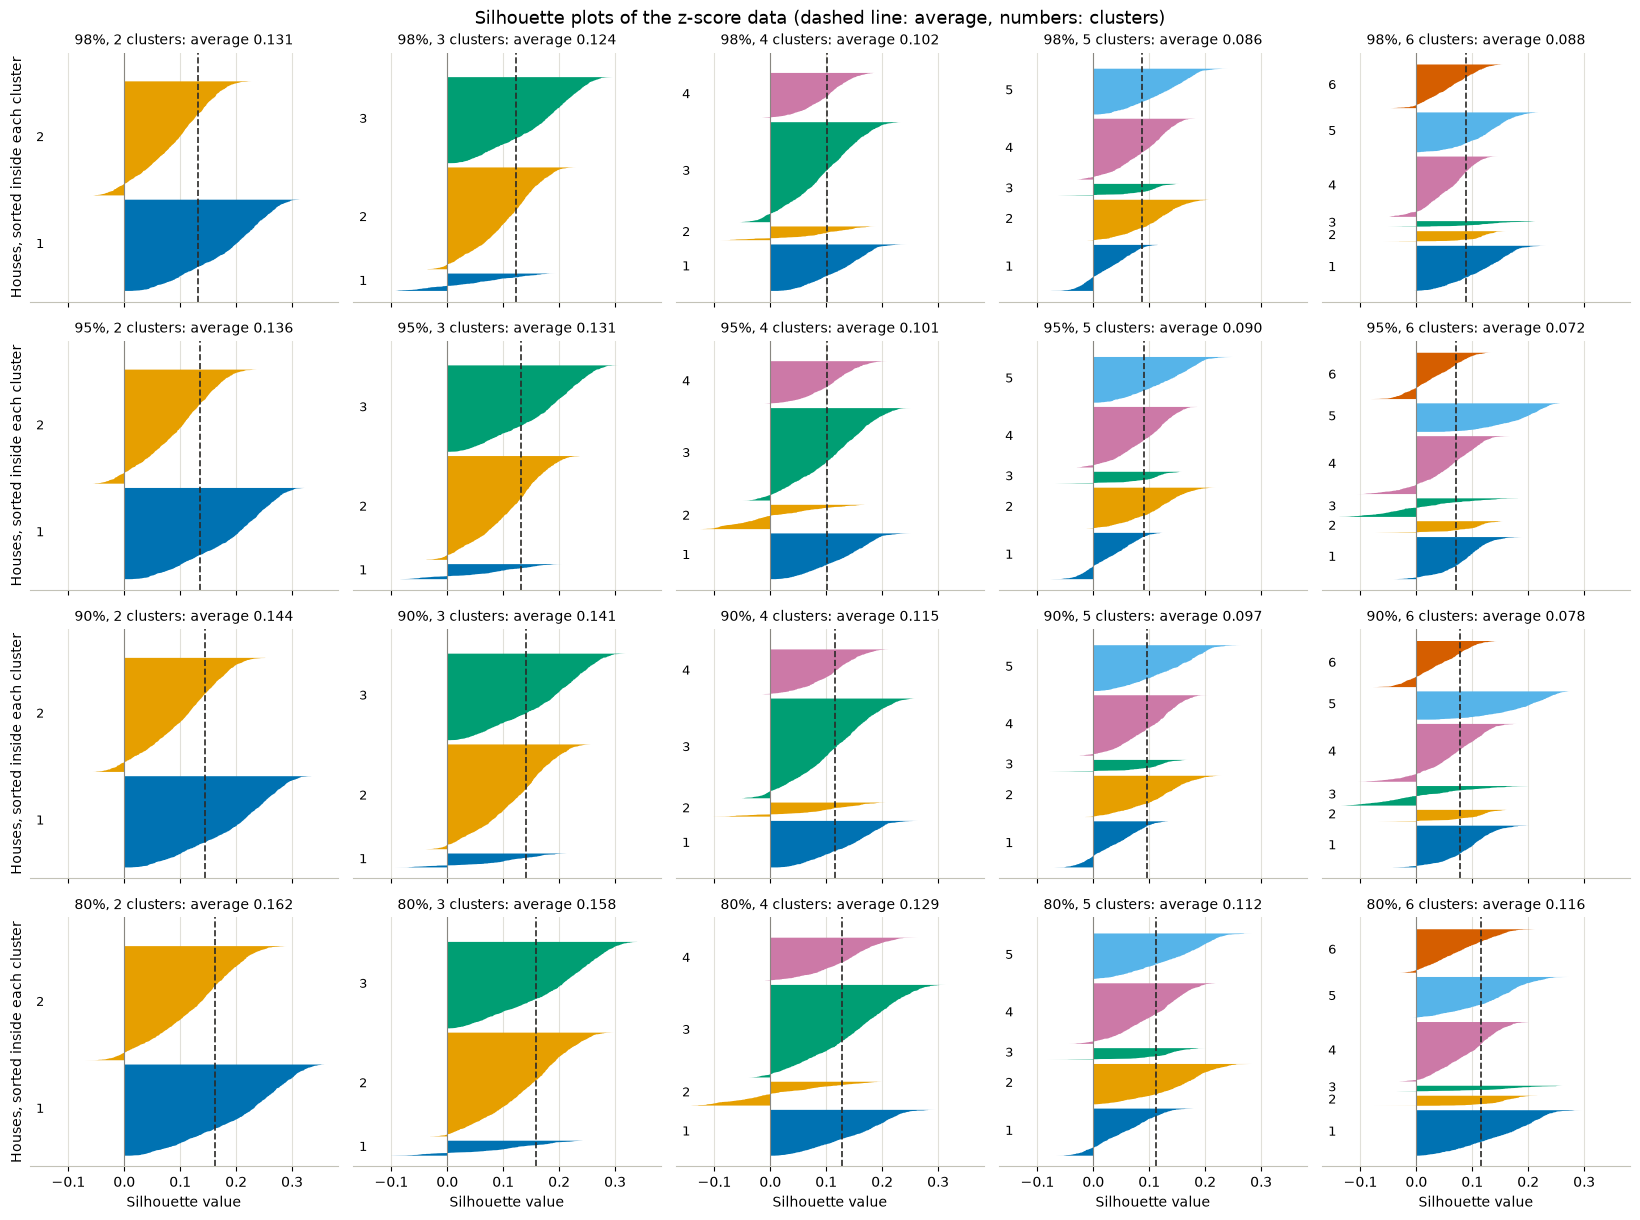

In [10]:
plot_silhouettes(
    reduced,
    component_counts,
    range(2, 7),
    "Silhouette plots of the z-score data (dashed line: average, numbers: clusters)",
)

In [11]:
silhouette = silhouette_table(reduced, component_counts, range(2, 9))

print("Average silhouette:")
display(silhouette.round(3))
print("Number of clusters with the highest average silhouette:")
print(silhouette.idxmax().to_string())

Average silhouette:


,98%,95%,90%,80%
Clusters,,,,
2,0.131,0.136,0.144,0.162
3,0.124,0.131,0.141,0.158
4,0.102,0.101,0.115,0.129
5,0.086,0.090,0.097,0.112
6,0.088,0.072,0.078,0.116
7,0.086,0.077,0.086,0.108
8,0.073,0.072,0.078,0.097


Number of clusters with the highest average silhouette:
98%    2
95%    2
90%    2
80%    2


#### Interpretation of the silhouette analysis
- **What the value means:** a house has a silhouette of `(b - a) / max(a, b)`, where `a` is its mean distance to its own cluster and `b` its mean distance to the closest other cluster. Near 1 the house clearly belongs where it is, near 0 it could belong to either cluster, and a negative value means that the other cluster is closer.
- **The figure:** each shape shows the houses of one cluster sorted by value, its thickness is the size of the cluster, and the dashed line marks the average.
- **Scores around 0.1:** the averages run from 0.072 to 0.162. At such values a house is only slightly closer to its own cluster than to the next one, so the clusters overlap strongly and no clean gaps exist between them. The groups are slices of one continuous cloud.
- **Few clusters score best:** 2 clusters lead at all thresholds. At 90% the average falls clearly: 0.144 for 2 clusters, 0.141 for 3, 0.115 for 4, 0.097 for 5 and 0.078 for 6. With a gap of about a third between 2 and 5 clusters, the silhouette argues against 5 clusters here.
- **Small clusters:** from 3 clusters on, the figure shows a thin cluster with many values below 0, for example cluster 1 at 3 clusters. With 5 clusters a thin cluster of about 166 houses remains, but its shape reaches clearly to the right of 0. Cluster 1 now holds the largest part below 0.
- **Lower thresholds:** the averages rise from 0.086 at 98% to 0.112 at 80% with 5 clusters. Dropping small components removes distance that all houses share, which widens the ratio between `a` and `b` without moving the houses.

### Choice of the number of clusters

In [12]:
test_threshold = 0.90
test_data = reduced[:, : component_counts[test_threshold]]
seeds = range(6)

rows = []
for k in range(2, 8):
    runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit_predict(test_data) for seed in seeds]
    pair_scores = [adjusted_rand_score(first, second) for first, second in combinations(runs, 2)]
    rows.append(
        {
            "Clusters": k,
            "Seed pairs": len(pair_scores),
            "Mean agreement": np.mean(pair_scores),
            "Lowest agreement": np.min(pair_scores),
            "Inertia drop (%)": drop_per_cluster.loc[k, "90%"],
            "Average silhouette": silhouette.loc[k, "90%"],
            "Cluster sizes (seed 0)": sorted(np.bincount(runs[0]).tolist()),
        }
    )

choice = pd.DataFrame(rows).set_index("Clusters")
with pd.option_context("display.max_colwidth", None):
    display(choice.round(3))

,Seed pairs,Mean agreement,Lowest agreement,Inertia drop (%),Average silhouette,Cluster sizes (seed 0)
Clusters,,,,,,
2,15,1.000,1.000,14.4,0.144,"[1299, 1624]"
3,15,0.944,0.879,5.4,0.141,"[331, 1214, 1378]"
4,15,0.916,0.830,4.6,0.115,"[217, 627, 661, 1418]"
5,15,0.979,0.962,4.0,0.097,"[165, 588, 650, 658, 862]"
6,15,0.872,0.775,2.6,0.078,"[166, 284, 395, 600, 656, 822]"
7,15,0.752,0.640,2.7,0.086,"[125, 160, 252, 432, 568, 574, 812]"


In [13]:
n_clusters = 5

rows = []
for seed in [*seeds, SEED]:
    model = KMeans(n_clusters=n_clusters, n_init=N_INIT, random_state=seed).fit(test_data)
    rows.append({"Seed": seed, "Inertia": model.inertia_, "Cluster sizes": sorted(np.bincount(model.labels_).tolist())})

print(f"Chosen number of clusters: {n_clusters}")
print(f"Runs at {test_threshold:.0%} of the variance with each seed:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Seed").round(1))

Chosen number of clusters: 5
Runs at 90% of the variance with each seed:


,Inertia,Cluster sizes
Seed,,
0,122044.1,"[165, 588, 650, 658, 862]"
1,122044.0,"[165, 585, 650, 657, 866]"
2,122040.7,"[166, 575, 651, 670, 861]"
3,122040.7,"[166, 575, 651, 670, 861]"
4,122040.7,"[166, 575, 651, 670, 861]"
5,122040.7,"[166, 575, 651, 670, 861]"
42,122043.9,"[166, 588, 652, 657, 860]"


#### Interpretation of the number of clusters
- **What was tried:** each number of clusters from 2 to 7 was fitted at 90% with six different seeds, which set the random start of k-means. Every pair of runs (15 pairs) was compared with the **adjusted Rand index**: it reaches 1 when two runs give the same grouping, however the clusters are numbered, and is around 0 for groupings that match only by chance.
- **What came out:** the agreement does not simply fall with more clusters. It is 1.000 for 2 clusters, drops to 0.944 for 3 and 0.916 for 4, and recovers to 0.979 for 5 with a lowest pair of 0.962. From 6 clusters on it falls again, to 0.872 and then 0.752.
- **Choice:** 5 clusters.
    - **Stability:** 5 clusters are more stable than 3 or 4, and agreement falls from 6 on. In the seed table the inertia stays between 122,040.7 and 122,044.1, and the seed 42 model used below lies in that range.
    - **Elbow:** the drop goes from 4.0% for the fifth cluster to 2.6% for the sixth, and it stays low after that.
    - **Detail:** 2 clusters would only cut the houses in half, into 1,299 and 1,624.
    - **Comparability:** notebooks 08, 08.1, 08.2 and 08.3 use one number of clusters, so their differences come from the preparation.
- **Evidence against it:** here the case for 5 is weaker than the numbers above suggest. The silhouette prefers 2 clusters (0.144) and 3 clusters (0.141) clearly over 5 (0.097), the strongest bend of the elbow is at 2 clusters, and 2 clusters are also the most stable. Looking at this notebook alone, 2 clusters would be a fair choice.
- **Rejected:** 2 clusters for the lack of detail and because the other notebooks need the same number. 3 and 4 clusters are less stable than 5. 6 and 7 clusters depend on the seed.
- **Unequal sizes:** the 5 clusters range from 165 to 862 houses in the seed 0 run, so one group is much smaller than the others.

### Final models and cluster scatter plots

In [14]:
models = fit_models(reduced, component_counts, n_clusters)
labels_at_98 = models[0.98].labels_

rows = []
for threshold, model in models.items():
    count = component_counts[threshold]
    values = silhouette_samples(reduced[:, :count], model.labels_)
    sizes = np.bincount(model.labels_)
    rows.append(
        {
            "Variance kept": f"{threshold:.0%}",
            "Components": count,
            **{f"Cluster {number}": size for number, size in enumerate(sizes, start=1)},
            "Inertia": model.inertia_,
            "Average silhouette": values.mean(),
            "Negative silhouette": (values < 0).mean(),
            "Houses not in their 98% cluster": (model.labels_ != labels_at_98).sum(),
        }
    )

final_models = pd.DataFrame(rows).set_index("Variance kept")
display(final_models.round(3))

,Components,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Inertia,Average silhouette,Negative silhouette,Houses not in their 98% cluster
Variance kept,,,,,,,,,,
98%,84,656,582,166,867,652,136203.616,0.086,0.088,0
95%,61,660,583,166,863,651,130843.277,0.090,0.083,5
90%,45,657,588,166,860,652,122043.877,0.097,0.070,15
80%,30,671,575,165,863,649,104763.597,0.112,0.056,53


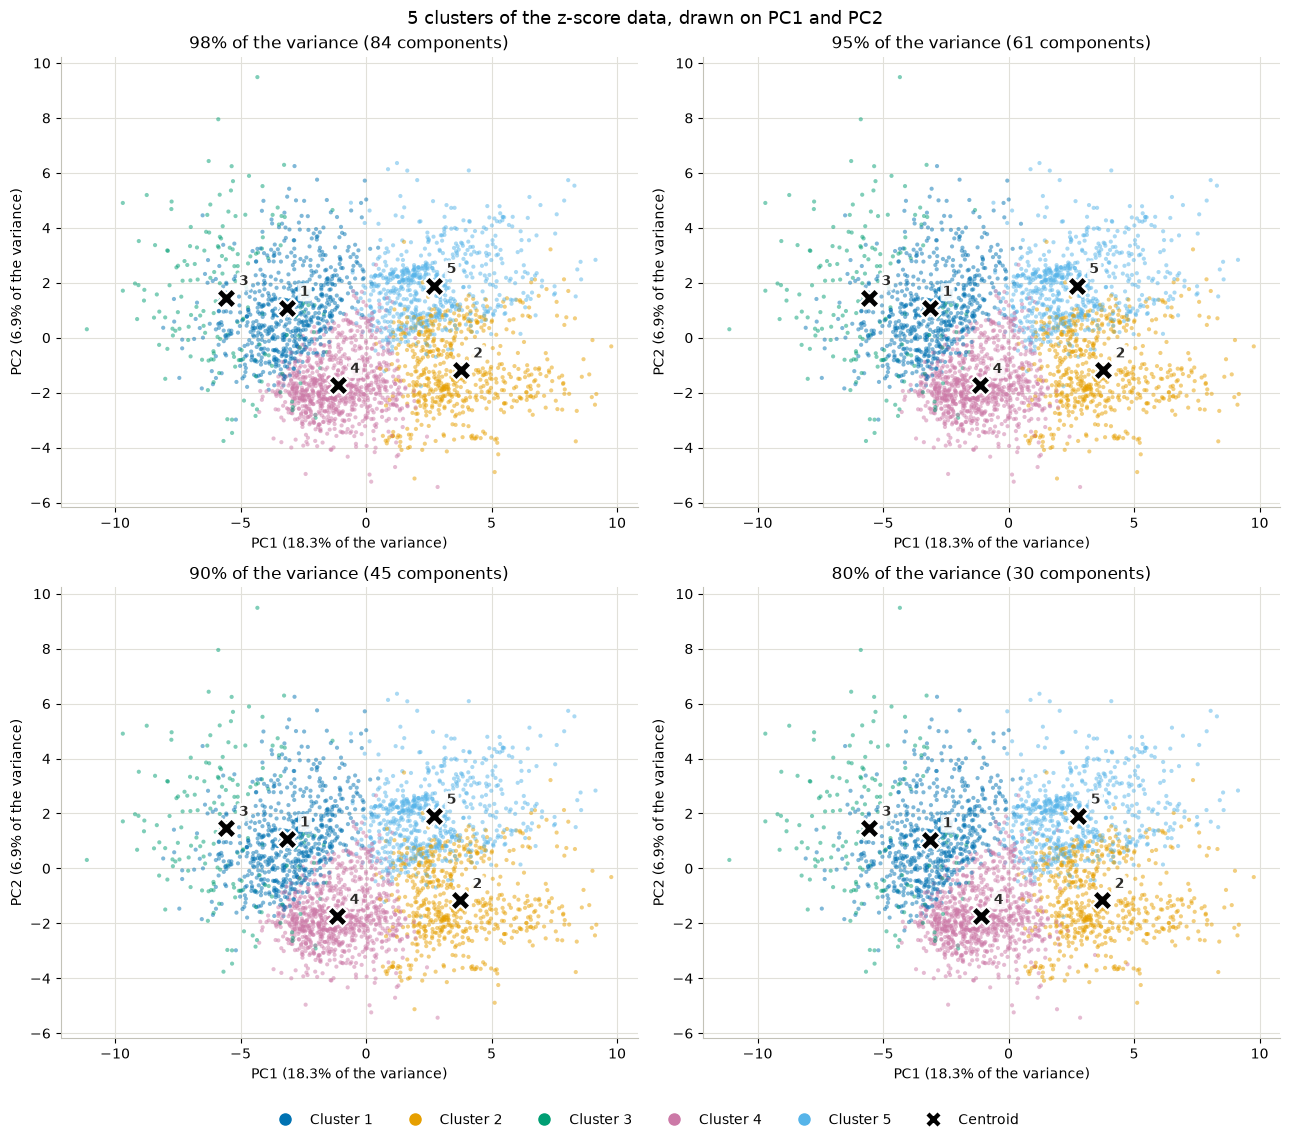

In [15]:
panels = {
    f"{threshold:.0%} of the variance ({component_counts[threshold]} components)": (pca, reduced, model)
    for threshold, model in models.items()
}
plot_clusters(panels, f"{n_clusters} clusters of the z-score data, drawn on PC1 and PC2")

In [16]:
threshold_agreement = agreement_table({f"{t:.0%}": model.labels_ for t, model in models.items()})
pair_scores = threshold_agreement.to_numpy()[np.triu_indices(len(threshold_agreement), k=1)]

centroid_shift = max(
    np.abs(model.cluster_centers_[:, :2] - models[0.98].cluster_centers_[:, :2]).max() for model in models.values()
)
visible = pd.Series({f"{t:.0%}": shares[:2].sum() / cumulative[count - 1] for t, count in component_counts.items()})

print("Adjusted Rand index between the thresholds:")
display(threshold_agreement.round(3))
print(f"Lowest agreement between two thresholds: {pair_scores.min():.3f}")
print(f"Largest move of a centroid on PC1 or PC2 compared with 98%: {centroid_shift:.3f}")
print(f"Standard deviation of the houses on PC1 / PC2: {reduced[:, 0].std():.3f} / {reduced[:, 1].std():.3f}")
print("Share of the kept variance that PC1 and PC2 show:")
print(visible.map("{:.1%}".format).to_string())

Adjusted Rand index between the thresholds:


,98%,95%,90%,80%
98%,1.000,0.995,0.985,0.951
95%,0.995,1.000,0.986,0.954
90%,0.985,0.986,1.000,0.957
80%,0.951,0.954,0.957,1.000


Lowest agreement between two thresholds: 0.951
Largest move of a centroid on PC1 or PC2 compared with 98%: 0.065
Standard deviation of the houses on PC1 / PC2: 3.382 / 2.077
Share of the kept variance that PC1 and PC2 show:
98%    25.7%
95%    26.5%
90%    28.0%
80%    31.3%


#### Interpretation of the final models
- **Are there differences?** Only small ones. From 98% to 90% the models differ by 5 and 15 houses from the 98% model. The 80% model differs more, by 53 of 2,923 houses, and it also has the lowest agreement with the others, 0.951 to 0.957, while the three higher thresholds stay at 0.985 or above. Cluster 3 stays the small one throughout, with 165 or 166 houses.
- **Same axes in every panel:** PC1 and PC2 are the first two columns of the same PCA, and each dataset only keeps fewer of the columns after them. The dots therefore stay in place from panel to panel. The centroids shift by at most 0.065, which is tiny next to the spread of the houses of 3.382 on PC1 and 2.077 on PC2.
- **Why the thresholds matter so little:** the components that separate the datasets are the small ones at the end, so the distances between houses barely change. The 80% model drops the most, 54 of the 84 components, and only then does the grouping shift noticeably.
- **What the scores do:** inertia goes from 136,204 at 98% to 104,764 at 80%, and the average silhouette from 0.086 to 0.112. Negative silhouettes fall from 8.8% to 5.6% of the houses. This follows from measuring fewer components, since nearly all houses stay where they were.
- **Overlap in the plot:** the panels show two dimensions of data that k-means saw in up to 84. These two hold 25.7% of the kept variance at 98% and 31.3% at 80%, so most of what separates the clusters is not visible. Cluster 3 is the clearest example. Its dots mix with those of cluster 1, and its centroid lies far to the left, although the two are separate groups in the full data.